<a href="https://colab.research.google.com/github/joshirdzdel-svg/estadisticainferencial2026A/blob/main/Unidad4_problemario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Analiza los siguientes diseños experimentales, e intenta sacar el máximo valor a la información. Verifica los supuestos (linealidad, homscedasticidad e independencia), puedes apoyarte en [la guía de la unidad 4](https://github.com/DrFaus/Estadistica2026B/blob/main/DiseniosExperimentalesUnFactor.ipynb). Aplica una prueba post-hoc en caso que sea necesario. Redacta una conclusión y una recomendación para las personas que recolectaron los datos.


1. **Comparación de cuatro métodos de ensamble:** Un equipo de mejora investiga el efecto de cuatro métodos de ensamble A, B, C y D, sobre el tiempo de ensamble en minutos. En primera instancia, la estrategia experimental es aplicar cuatro veces los cuatro métodos de ensamble en orden completamente aleatorio (las 16 pruebas en orden aleatorio). Los tiempos de ensamble obtenidos se muestran en la tabla 3.1. Si se usa el diseño completamente al azar (DCA), se supone que, además del método de ensamble, no existe ningún otro factor que influya de manera significativa sobre la variable de respuesta (tiempo de ensamble).

| Método de ensamble | A  | B  | C  | D  |
|--------------------|----|----|----|----|
|                    | 6  | 7  | 11 | 10 |
|                    | 8  | 9  | 16 | 12 |
|                    | 7  | 10 | 11 | 11 |
|                    | 8  | 8  | 13 | 9  |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
metodo_de_ensamble,tiempo_de_ensamble
A, 6
A, 8
A, 7
A, 8
B, 7
B, 9
B, 10
B, 8
C, 11
C, 16
C, 11
C, 13
D, 10
D, 12
D, 11
D, 9

'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,metodo_de_ensamble,tiempo_de_ensamble
0,A,6
1,A,8
2,A,7
3,A,8
4,B,7
5,B,9
6,B,10
7,B,8
8,C,11
9,C,16


In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols
import sys

# Hipótesis:
# H0: A = B = C = D
# H1: al menos un metodo es diferente

if 'C' in globals():
  del C
modelo = ols('tiempo_de_ensamble ~ C(metodo_de_ensamble)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.

,sum_sq,df,F,PR(>F)
C(metodo_de_ensamble),69.5,3.0,9.4237,0.0018
Residual,29.5,12.0,NaN,NaN


Se implementa la tabla de anova para comparar los tiempos de los  cuatro métodos.

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
     A      B     1.25 0.6805 -2.0416 4.5416  False
     A      C      5.5 0.0016  2.2084 8.7916   True
     A      D     3.25 0.0533 -0.0416 6.5416  False
     B      C     4.25  0.011  0.9584 7.5416   True
     B      D      2.0 0.3181 -1.2916 5.2916  False
     C      D    -2.25 0.2309 -5.5416 1.0416  False
---------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

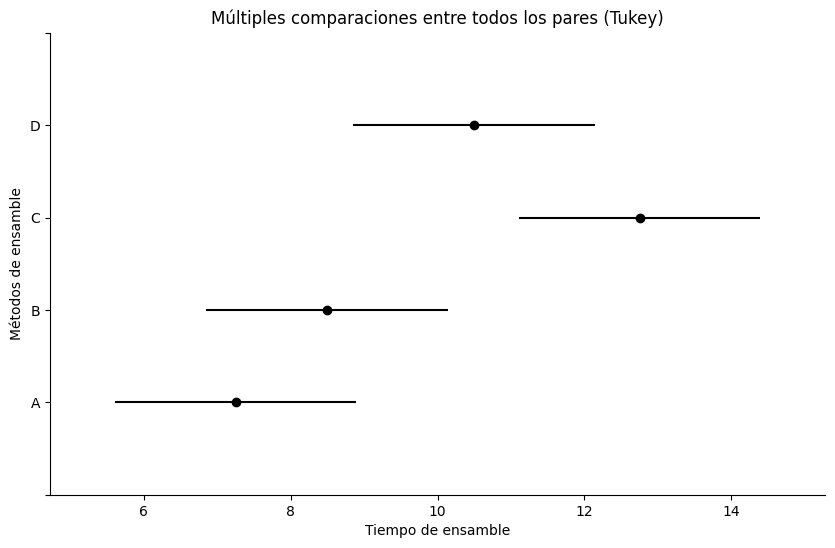

In [ ]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['tiempo_de_ensamble'], # Variable de respuesta
    groups=df['metodo_de_ensamble'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Métodos de ensamble", xlabel="Tiempo de ensamble")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

Se utilizo el metodo tukey para poder identificar específicamente cuáles métodos presentan diferencias significativas, como en esete caaso poder observar que los cuatro metodos tienen similitudes.

In [ ]:

residuales = modelo.resid


valor-p (Shapiro) = 0.2808008139238357


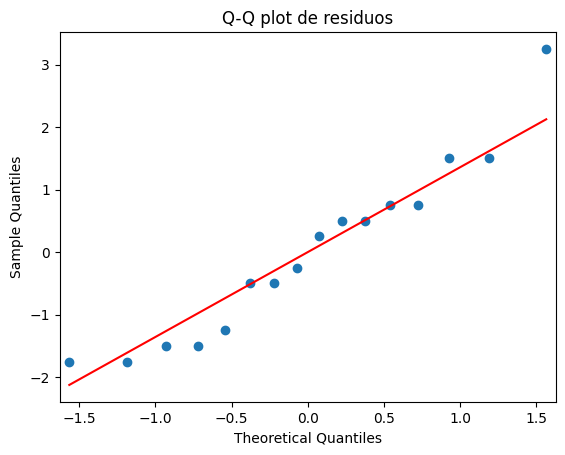

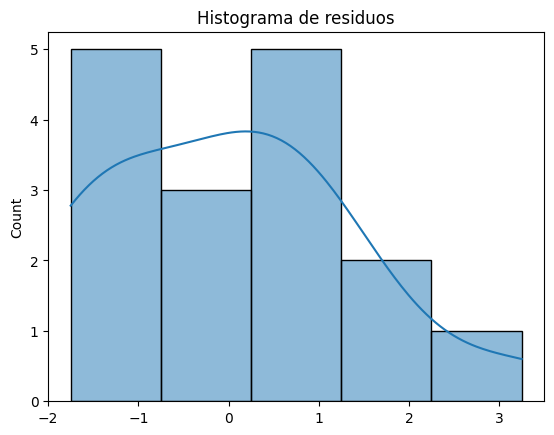

In [ ]:

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se aplicó para poder comprobar si los residuales del anova seguían una distribución normal.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
A = df[df['metodo_de_ensamble'] == 'A']['tiempo_de_ensamble']
B = df[df['metodo_de_ensamble'] == 'B']['tiempo_de_ensamble']
C = df[df['metodo_de_ensamble'] == 'C']['tiempo_de_ensamble']
D = df[df['metodo_de_ensamble'] == 'D']['tiempo_de_ensamble']

stat, p = levene(A, B, C, D)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")


Estadístico de Levene: 0.9474
p-valor: 0.4485


se realizó la prueba de levene para verificar si la variabilidad de los tiempos era similar entre los cuatro métodos. Se obtuvo un valor p de 0.4485, por lo que no se encontraron diferencias significativas entre las varianzas.

2. **Comparación de cuatro tipos de cuero:** Un fabricante de calzado desea mejorar la calidad de las suelas, las cuales se pueden hacer con uno de los cuatro tipos de cuero A, B, C y D disponibles en el mercado. Para ello, prueba los cueros con una máquina que hace pasar los zapatos por una superficie abrasiva; la suela de éstos se desgasta al pasarla por dicha superficie. Como criterio de desgaste se usa la pérdida de peso después de un número fijo de ciclos. Se prueban en orden aleatorio 24 zapatos, seis de cada tipo de cuero. Al hacer las pruebas en orden completamente al azar se evitan sesgos y las mediciones en un tipo de cuero resultan independientes de las demás. Los datos (en miligramos) sobre el desgaste de cada tipo de cuero se muestran en la tabla.

| Tipo de cuero | Observaciones                  | Promedio |
|---------------|--------------------------------|----------|
| A             | 264, 260, 258, 241, 262, 255 | 256.7    |
| B             | 208, 220, 216, 200, 213, 206 | 209.8    |
| C             | 220, 263, 219, 225, 230, 228 | 230.8    |
| D             | 217, 226, 215, 227, 220, 222 | 220.7    |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
tipo_de_cuero,desgaste_de_la_suela
A, 264
A, 260
A, 258
A, 241
A, 262
A, 255
B, 208
B, 220
B, 216
B, 200
B, 213
B, 206
C, 220
C, 263
C, 219
C, 225
C, 230
C, 228
D, 217
D, 226
D, 215
D, 227
D, 220
D, 222

'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,tipo_de_cuero,desgaste_de_la_suela
0,A,264
1,A,260
2,A,258
3,A,241
4,A,262
5,A,255
6,B,208
7,B,220
8,B,216
9,B,200


In [ ]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols
if 'C' in globals():
  del C

# respuesta ~ C(factor)
modelo = ols('desgaste_de_la_suela ~ C(tipo_de_cuero)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(14)


,sum_sq,df,F,PR(>F)
C(tipo_de_cuero),7019.458333,3.0,22.755356,0.000001
Residual,2056.500000,20.0,NaN,NaN


Se realizó la tabla de anova para comprobar si los cuatro tipos de cuero presentaban diferencias en el desgaste promedio. Se encontraron diferencias significativas entre los tipos de cuero, por lo que no todos tienen el mismo comportamiento, por lo que se realisara la prueba de shapiro-wilk para revisar si siguin una dsitribucion normal.

valor-p (Shapiro) = 0.00967014513830024


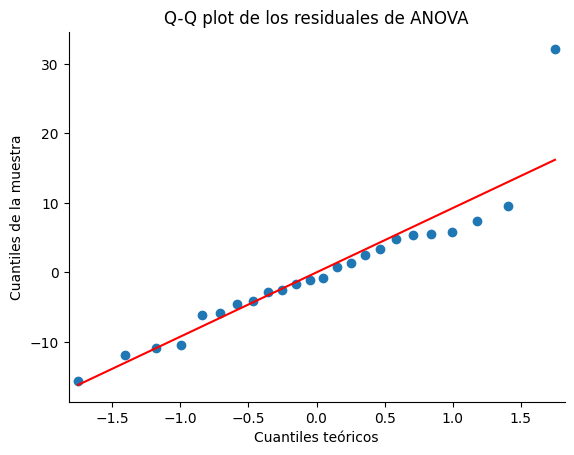

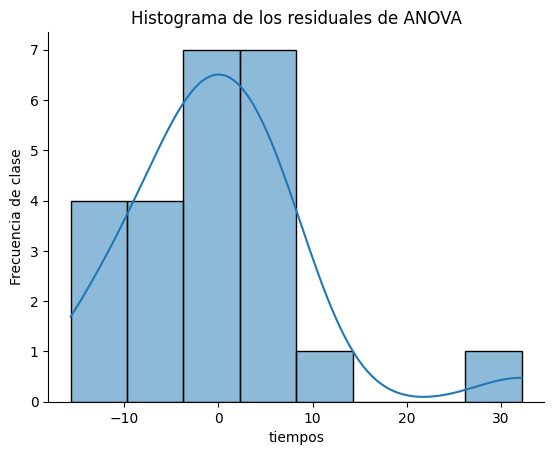

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

El valor p fue de 0.0097, menor a 0.05, nos indica que no se cumplía adecuadamente el supuesto de normalidad por lo que seguimos con el test de levene.

In [ ]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tipo_1 = df[df['tipo_de_cuero'] == "A"]["desgaste_de_la_suela"]
tipo_2 = df[df['tipo_de_cuero'] == "B"]["desgaste_de_la_suela"]
tipo_3 = df[df['tipo_de_cuero'] == "C"]["desgaste_de_la_suela"]
tipo_4 = df[df['tipo_de_cuero'] == "D"]["desgaste_de_la_suela"]

estadistico, valor_p_levene = levene(
    tipo_1,
    tipo_2,
    tipo_3,
    tipo_4,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")



Test de Levene (Brown-Forsythe)
Estadístico = 0.5797
Valor-p = 0.6351


con este test podemos comprobar que las varianzas de los cuatro tipos de cuero eran similares ya que se obtuvo un valor p de 0.6351, que nos indica que este supuesto sí se cumplía.

Lambda óptimo: -3.7078


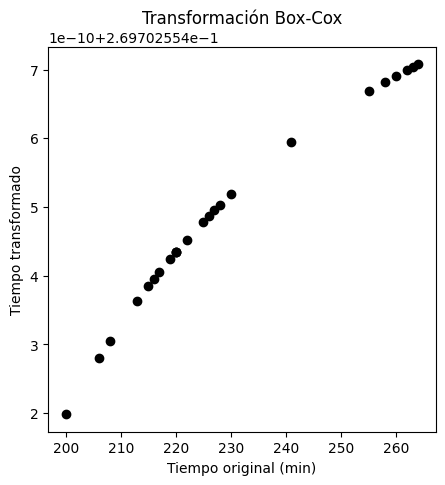

In [ ]:

from scipy.stats import boxcox
import matplotlib.pyplot as plt

# Transformación Box-Cox
# Requiere que todos los valores sean mayores que cero

df["desgaste_boxcox"], lambda_opt = boxcox(df["desgaste_de_la_suela"])

print(f"Lambda óptimo: {lambda_opt:.4f}")

# Visualización de la transformación
plt.figure(figsize=(5, 5), dpi=100)

plt.scatter(df["desgaste_de_la_suela"], df["desgaste_boxcox"],
            color="black")

plt.title("Transformación Box-Cox")
plt.xlabel("Tiempo original (min)")
plt.ylabel("Tiempo transformado")
plt.show()


Se aplicó box_cox debido a que los datos originales no cumplían con el supuesto de normalidad. Después de transformar los datos, se obtuvo una mejor distribución de los residuales

In [ ]:
df

,tipo_de_cuero,desgaste_de_la_suela,desgaste_boxcox
0,A,264,0.269703
1,A,260,0.269703
2,A,258,0.269703
3,A,241,0.269703
4,A,262,0.269703
5,A,255,0.269703
6,B,208,0.269703
7,B,220,0.269703
8,B,216,0.269703
9,B,200,0.269703


In [ ]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('desgaste_boxcox ~ C(tipo_de_cuero)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4)


,sum_sq,df,F,PR(>F)
C(tipo_de_cuero),0.0,3.0,23.3682,0.0
Residual,0.0,20.0,NaN,NaN


Se volvió a realizar para comprobar las diferencias entre los tipos de cuero después de mejorar el comportamiento de los datos. Se mantuvo la existencia de diferencias significativas.

valor-p (Shapiro) = 0.4576953738713335


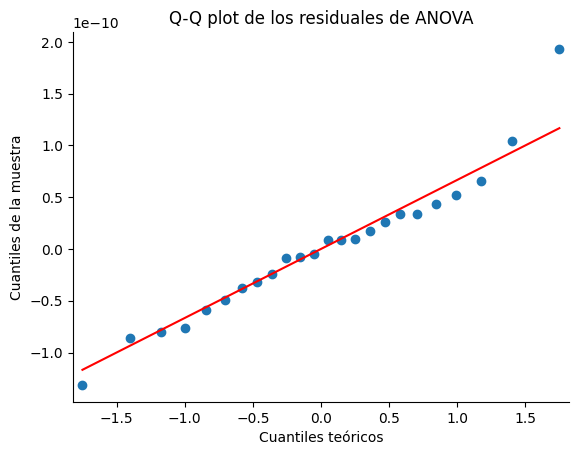

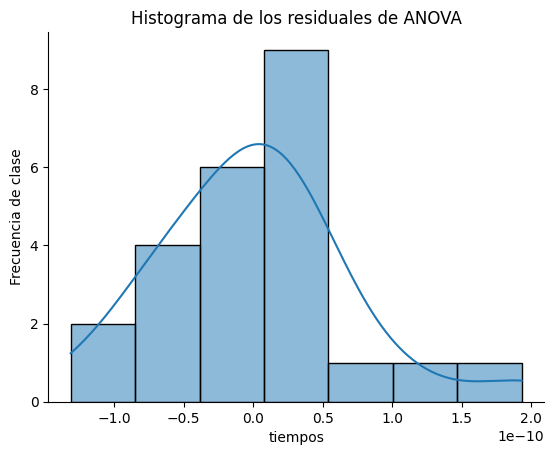

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

se utilizó nuevamente para comprobar si la transformación había mejorado la normalidad. Se obtuvo un valor p de 0.4577, por lo que ahora sí se cumple este supuesto

In [ ]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

tipo_1 = df[df['tipo_de_cuero'] == "A"]["desgaste_boxcox"]
tipo_2 = df[df['tipo_de_cuero'] == "B"]["desgaste_boxcox"]
tipo_3 = df[df['tipo_de_cuero'] == "C"]["desgaste_boxcox"]
tipo_4 = df[df['tipo_de_cuero'] == "D"]["desgaste_boxcox"]

estadistico, valor_p_levene = levene(
    tipo_1,
    tipo_2,
    tipo_3,
    tipo_4,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")


Test de Levene (Brown-Forsythe)
Estadístico = 1.1788
Valor-p = 0.3428


Se utilizo el test de levene para comprobar nuevamente la igualdad de las varianzas.

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower upper reject
------------------------------------------------
     A      B     -0.0    0.0  -0.0  -0.0   True
     A      C     -0.0 0.0048  -0.0  -0.0   True
     A      D     -0.0 0.0001  -0.0  -0.0   True
     B      C      0.0 0.0018   0.0   0.0   True
     B      D      0.0 0.0613  -0.0   0.0  False
     C      D     -0.0  0.401  -0.0   0.0  False
------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

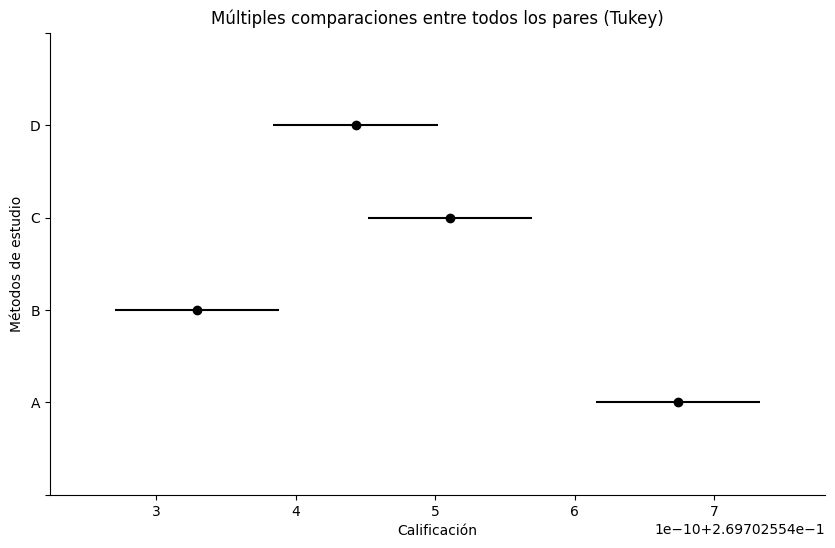

In [ ]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['desgaste_boxcox'], # Variable de respuesta
    groups=df['tipo_de_cuero'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Métodos de estudio", xlabel="Calificación")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

Se aplicó para identificar qué tipos de cuero presentaban diferencias significativas. Se encontraron diferencias entre A y B, A y C, A y D, así como entre B y C. No se encontraron diferencias significativas entre B y D ni entre C y D.

In [ ]:
!pip install scikit-posthocs

In [ ]:
import scikit_posthocs as sp

# Dunn test con corrección de Bonferroni
resultado = sp.posthoc_dunn(
    df,
    val_col="desgaste_boxcox",
    group_col="tipo_de_cuero",
    p_adjust="bonferroni"
)

resultado.round(4)

,A,B,C,D
A,1.0000,0.0004,0.7835,0.0761
B,0.0004,1.0000,0.0761,0.7835
C,0.7835,0.0761,1.0000,1.0000
D,0.0761,0.7835,1.0000,1.0000


In [ ]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(tipo_de_cuero)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

η² (tamaño de efecto): 0.778


In [ ]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["tipo_de_cuero"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

η² = 0.7780
f de Cohen = 1.8722
Potencia de la prueba = 1.0000


In [ ]:
n_necesario = analisis_potencia.solve_power(
 effect_size=f_cohen,
 alpha=0.05,
 power=0.80, # Potencia de la prueba
 k_groups=k_grupos
)
print(f"Observaciones totales necesarias: {n_necesario:.2f}")
print(f"Observaciones por grupo: {np.ceil(n_necesario / k_grupos):.0f}")

Observaciones totales necesarias: 8.20
Observaciones por grupo: 3


3. En un centro de investigación se realiza un estudio para comparar varios tratamientos que, al aplicarse previamente a los frijoles crudos, reducen su tiempo de cocción. Estos tratamientos son a base de bicarbonato de sodio y cloruro de sodio o sal común. El primer tratamiento ($T_1$) es el de control, que consiste en no aplicar ningún tratamiento. El tratamiento $T_2$ es el remojo en agua con bicarbonato de sodio, el $T_3$ es remojar en agua con sal común y el $T_4$ es remojar en agua con una combinación de ambos ingredientes en proporciones iguales. La variable de respuesta es el tiempo de cocción en minutos. Los datos se muestran en la siguiente tabla:

| $T_1$ | $T_2$  | $T_3$  | $T_4$  |
|---------|-----|-----|-----|
| 213     | 76  | 57  | 84  |
| 214     | 85  | 67  | 82  |
| 204     | 74  | 55  | 85  |
| 208     | 78  | 64  | 92  |
| 212     | 82  | 61  | 87  |
| 200     | 75  | 63  | 79  |
| 207     | 82  | 63  | 90  |



In [ ]:
import pandas as pd
from io import StringIO

datos = '''
tratamientos,tiempo_de_coccion
T1, 213
T1, 214
T1, 204
T1, 208
T1, 212
T1, 200
T1, 207
T2, 76
T2, 85
T2, 74
T2, 78
T2, 82
T2, 75
T2, 82
T3, 57
T3, 67
T3, 55
T3, 64
T3, 61
T3, 63
T3, 63
T4, 84
T4, 82
T4, 85
T4, 92
T4, 87
T4, 79
T4, 90
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,tratamientos,tiempo_de_coccion
0,T1,213
1,T1,214
2,T1,204
3,T1,208
4,T1,212
5,T1,200
6,T1,207
7,T2,76
8,T2,85
9,T2,74


In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente
if 'C' in globals():
  del C
modelo = ols('tiempo_de_coccion ~ C(tratamientos)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.


,sum_sq,df,F,PR(>F)
C(tratamientos),95041.2500,3.0,1558.966,0.0
Residual,487.7143,24.0,NaN,NaN


se utilizo para comprobar si los cuatro tratamientos producían diferencias en el tiempo de cocción, pero como se obtuvo un valor p muy pequeño menor a 0.05, nos indica que existen diferencias significativas entre los tratamientos.

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2  meandiff p-adj    lower     upper   reject
---------------------------------------------------------
    T1     T2 -129.4286    0.0 -136.0757 -122.7815   True
    T1     T3 -146.8571    0.0 -153.5043   -140.21   True
    T1     T4 -122.7143    0.0 -129.3614 -116.0672   True
    T2     T3  -17.4286    0.0  -24.0757  -10.7815   True
    T2     T4    6.7143 0.0471    0.0672   13.3614   True
    T3     T4   24.1429    0.0   17.4957     30.79   True
---------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

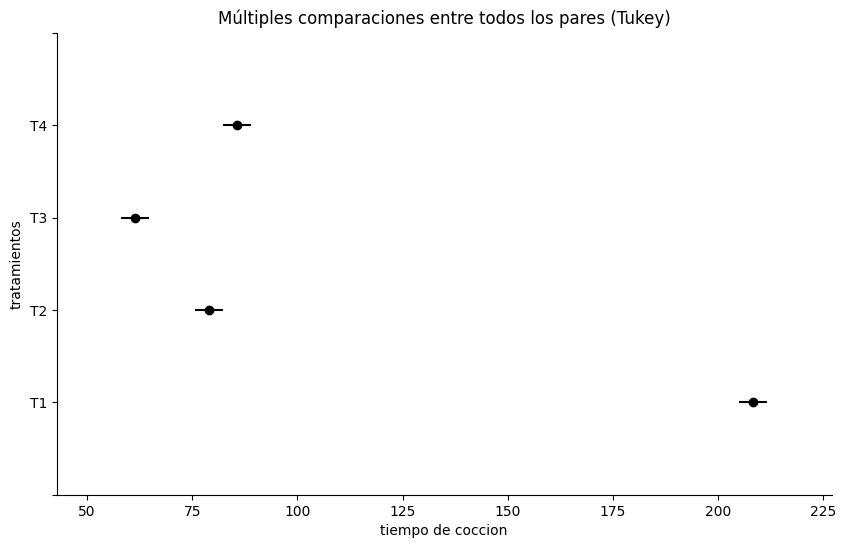

In [ ]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['tiempo_de_coccion'], # Variable de respuesta
    groups=df['tratamientos'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="tratamientos", xlabel="tiempo de coccion")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

Se utilizó para identificar cuáles tratamientos tenían tiempos de cocción diferentes. Los resultados mostraron que todos los tratamientos presentan diferencias significativas entre sí.

In [ ]:
residuales = modelo.resid

valor-p (Shapiro) = 0.34689165649616827


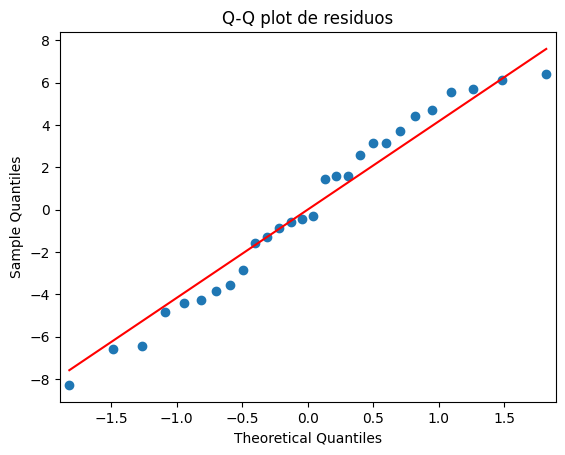

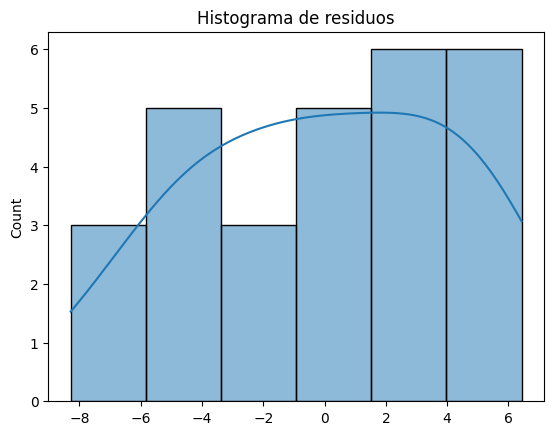

In [ ]:

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

aqui se aplicó la prueba de shpiro-wilk para comprobar la normalidad de los residuales ya que se pudo obtener un valor p de 0.3469, por lo que se considera que se cumple el supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
T1 = df[df['tratamientos'] == 'T1']['tiempo_de_coccion']
T2 = df[df['tratamientos'] == 'T2']['tiempo_de_coccion']
T3 = df[df['tratamientos'] == 'T3']['tiempo_de_coccion']
T4 = df[df['tratamientos'] == 'T4']['tiempo_de_coccion']

stat, p = levene(T1, T2, T3, T4)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

Estadístico de Levene: 0.1631
p-valor: 0.9201


al final se realizó para comprobar si las varianzas de los tratamientos eran similares por lo que se obtuvo un valor p de 0.9201 que nos indica que encontraron diferencias significativas en la variabilidad en resumen no se llegaron a encontrar diferencias en los tiempos de coccion.

4. Para estudiar la confiabilidad de ciertos tableros electrónicos para carros, se someten a un envejecimiento acelerado durante 100 horas a determinada temperatura, y como variable de interés se mide la intensidad de corriente que circula entre dos puntos, cuyos valores aumentan con el deterioro. Se probaron 20 módulos repartidos de manera equitativa en cinco temperaturas y los resultados obtenidos fueron los siguientes:

| 20°C | 40°C | 60°C | 80°C | 100°C |
|------|------|------|------|-------|
| 15   | 17   | 23   | 28   | 45    |
| 18   | 21   | 19   | 32   | 51    |
| 13   | 11   | 25   | 34   | 57    |
| 12   | 16   | 22   | 31   | 48    |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
temperatura,intensidad_de_corriente
grupo_20, 15
grupo_20, 18
grupo_20, 13
grupo_20, 12
grupo_40, 17
grupo_40, 21
grupo_40, 11
grupo_40, 16
grupo_60, 23
grupo_60, 19
grupo_60, 25
grupo_60, 22
grupo_80, 28
grupo_80, 32
grupo_80, 34
grupo_80, 31
grupo_100, 45
grupo_100, 51
grupo_100, 57
grupo_100, 48
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,temperatura,intensidad_de_corriente
0,grupo_20,15
1,grupo_20,18
2,grupo_20,13
3,grupo_20,12
4,grupo_40,17
5,grupo_40,21
6,grupo_40,11
7,grupo_40,16
8,grupo_60,23
9,grupo_60,19


In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente
if 'C' in globals():
  del C
modelo = ols('intensidad_de_corriente ~ C(temperatura)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.


,sum_sq,df,F,PR(>F)
C(temperatura),3411.8,4.0,68.0545,0.0
Residual,188.0,15.0,NaN,NaN


Se realizó para determinar si las diferentes temperaturas provocaban cambios significativos en la intensidad de corriente ya que se obtuvo un valor p menor a 0.05, por lo que se concluye que la temperatura sí influye en los resultados

    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
  group1   group2  meandiff p-adj   lower    upper   reject
-----------------------------------------------------------
grupo_100 grupo_20   -35.75    0.0 -43.4801 -28.0199   True
grupo_100 grupo_40    -34.0    0.0 -41.7301 -26.2699   True
grupo_100 grupo_60    -28.0    0.0 -35.7301 -20.2699   True
grupo_100 grupo_80    -19.0    0.0 -26.7301 -11.2699   True
 grupo_20 grupo_40     1.75 0.9535  -5.9801   9.4801  False
 grupo_20 grupo_60     7.75 0.0493   0.0199  15.4801   True
 grupo_20 grupo_80    16.75 0.0001   9.0199  24.4801   True
 grupo_40 grupo_60      6.0 0.1696  -1.7301  13.7301  False
 grupo_40 grupo_80     15.0 0.0002   7.2699  22.7301   True
 grupo_60 grupo_80      9.0 0.0191   1.2699  16.7301   True
-----------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

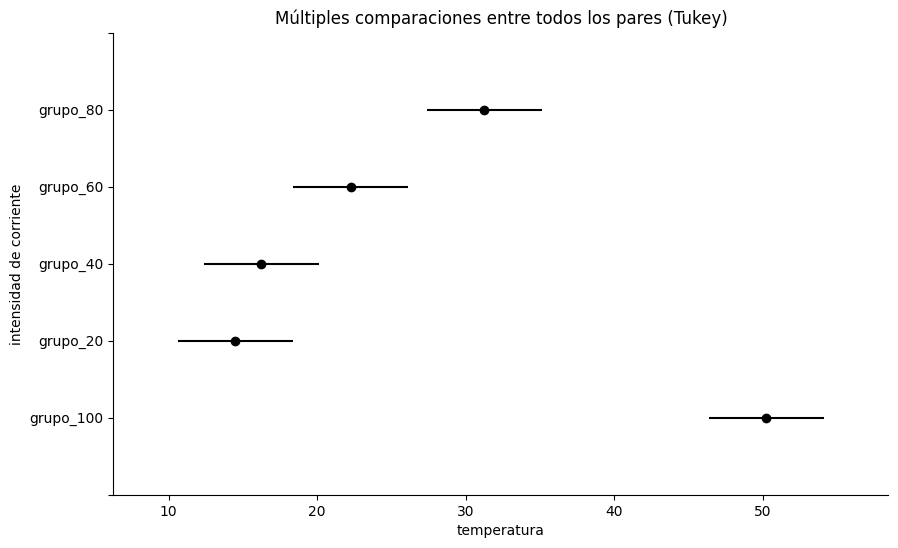

In [ ]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['intensidad_de_corriente'], # Variable de respuesta
    groups=df['temperatura'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="intensidad de corriente", xlabel= "temperatura")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")


Se realizó para identificar entre cuáles temperaturas existían diferencias significativas. Los resultados nos mostraron que 100 °C presenta mas diferencias con todas las demás temperaturas.

In [ ]:

residuales = modelo.resid

valor-p (Shapiro) = 0.7785351257478148


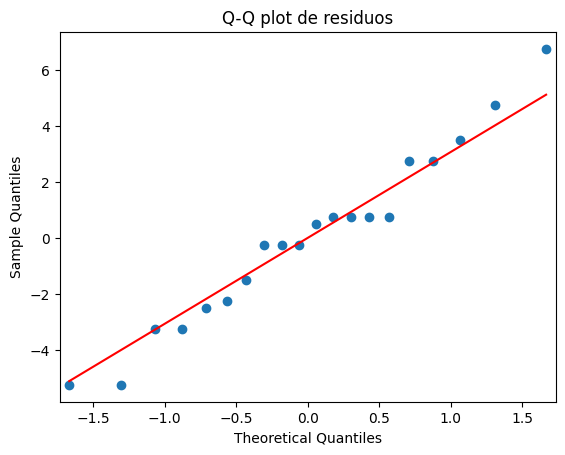

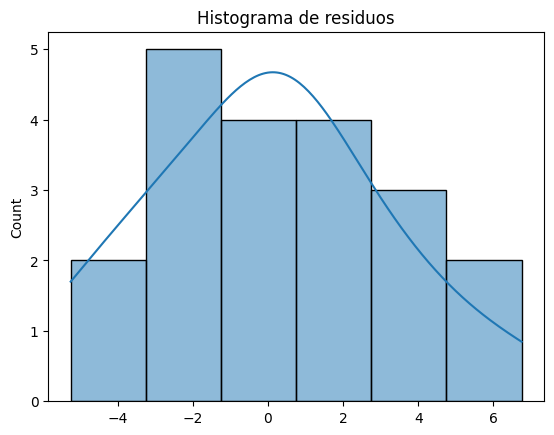

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se utilizó para comprobar si los residuales presentaban una distribución normal. Se obtuvo un valor p de 0.7785, por lo que se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
grupo_20 = df[df['temperatura'] == 'grupo_20']['intensidad_de_corriente']
grupo_40 = df[df['temperatura'] == 'grupo_40']['intensidad_de_corriente']
grupo_80 = df[df['temperatura'] == 'grupo_80']['intensidad_de_corriente']
grupo_100 = df[df['temperatura'] == 'grupo_100']['intensidad_de_corriente']

stat, p = levene(grupo_20, grupo_40, grupo_80, grupo_100)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")


Estadístico de Levene: 0.6652
p-valor: 0.5893


se utilizo para comprobar si las varianzas eran similares entre las cinco temperaturas. Al considerar los cinco grupos, se obtuvo un valor p de 0.6160, por lo que se cumple el supuesto de igualdad de varianzas.

5. En una empresa de manufactura se propone un tratamiento para reducir el porcentaje de productos defectuosos. Para validar esta propuesta se diseñó un experimento en el que se producía con o sin la propuesta de mejora. Cada corrida experimental consistió en producir un lote y la variable de respuesta es el porcentaje de producto defectuoso. Se hicieron 25 réplicas para cada tratamiento. Los datos obtenidos se muestran a continuación:

| Tratamiento     | Porcentaje de producto defectuoso                                     |
|-----------------|----------------------------------------------------------------------|
| Con tratam.     | 5.3, 4.0, 4.0, 4.0, 2.6, 2.1, 5.1, 4.1, 4.1, 3.2, 5.1, 2.2, 4.1     |
| Sin tratam.     | 8.0, 13.2, 7.2, 8.2, 9.1, 6.7, 12.6, 16.3, 9.2, 6.4, 7.2, 17.2, 12.3 |


In [ ]:

import pandas as pd
from io import StringIO

datos = '''
tratamiento,porcentaje_de_producto_defectuoso
con_tratam, 5.3
con_tratam, 4.0
con_tratam, 4.0
con_tratam, 4.0
con_tratam, 2.6
con_tratam, 2.1
con_tratam, 5.1
con_tratam, 4.1
con_tratam, 4.1
con_tratam, 3.2
con_tratam, 5.1
con_tratam, 2.2
con_tratam, 4.1
sin_tratam, 8.0
sin_tratam, 13.2
sin_tratam, 7.2
sin_tratam, 8.2
sin_tratam, 9.1
sin_tratam, 6.7
sin_tratam, 12.6
sin_tratam, 16.3
sin_tratam, 9.2
sin_tratam, 6.4
sin_tratam, 7.2
sin_tratam, 17.2
sin_tratam, 12.3
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df


,tratamiento,porcentaje_de_producto_defectuoso
0,con_tratam,5.3
1,con_tratam,4.0
2,con_tratam,4.0
3,con_tratam,4.0
4,con_tratam,2.6
5,con_tratam,2.1
6,con_tratam,5.1
7,con_tratam,4.1
8,con_tratam,4.1
9,con_tratam,3.2


In [ ]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('porcentaje_de_producto_defectuoso ~ C(tratamiento)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(14)


,sum_sq,df,F,PR(>F)
C(tratamiento),269.449615,1.0,37.102806,0.000003
Residual,174.293846,24.0,NaN,NaN


e realizó para comprobar si aplicar el tratamiento producía una reducción significativa en el porcentaje de productos defectuosos. Se obtuvo un valor p de 0.000003, menor a 0.05, por lo que existe una diferencia significativa entre los dos grupos.

valor-p (Shapiro) = 0.08240142335256262


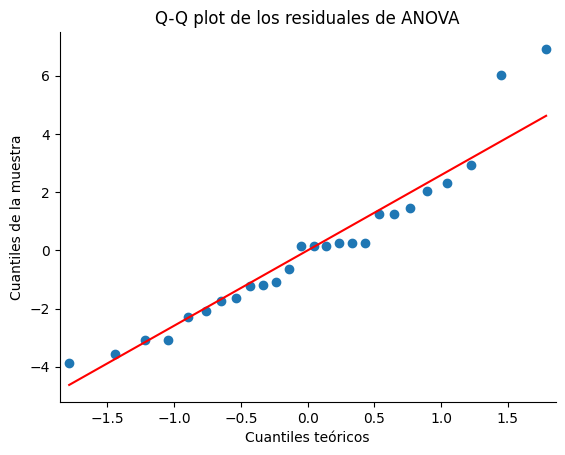

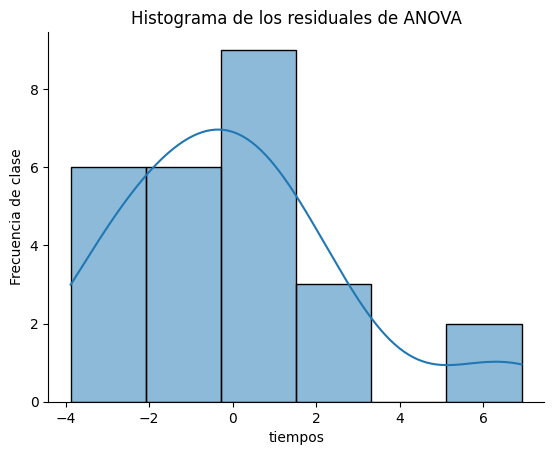

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

Se aplicó para comprobar si los residuales seguían una distribución normal. Se obtuvo un valor p de 0.0824, por lo que se considera que sí se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

con_tratam = df[df['tratamiento'] == "con_tratam"]["porcentaje_de_producto_defectuoso"]
sin_tratam = df[df['tratamiento'] == "sin_tratam"]["porcentaje_de_producto_defectuoso"]

estadistico, valor_p_levene = levene(
   con_tratam ,
   sin_tratam ,
    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")



Test de Levene (Brown-Forsythe)
Estadístico = 8.7144
Valor-p = 0.0070


Se utilizó para comprobar si las varianzas de los grupos eran similares. Se obtuvo un valor p de 0.0070, por lo que se identificaron diferencias significativas en la variabilidad.

Lambda óptimo: -0.0539


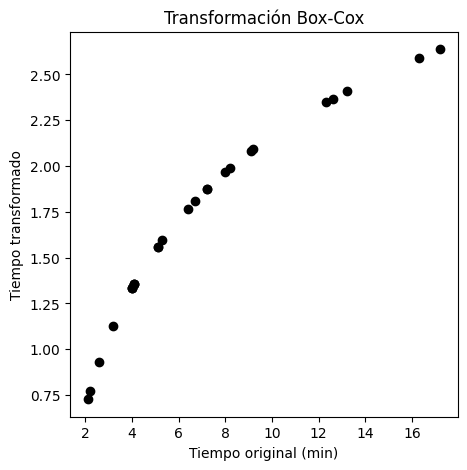

In [ ]:

from scipy.stats import boxcox
import matplotlib.pyplot as plt

# Transformación Box-Cox
# Requiere que todos los valores sean mayores que cero

df["porcentaje_de_producto_defectuoso_boxcox"], lambda_opt = boxcox(df["porcentaje_de_producto_defectuoso"])

print(f"Lambda óptimo: {lambda_opt:.4f}")

# Visualización de la transformación
plt.figure(figsize=(5, 5), dpi=100)

plt.scatter(df["porcentaje_de_producto_defectuoso"], df["porcentaje_de_producto_defectuoso_boxcox"],
            color="black")

plt.title("Transformación Box-Cox")
plt.xlabel("Tiempo original (min)")
plt.ylabel("Tiempo transformado")
plt.show()


Se aplicó debido a que no se cumplía el supuesto de igualdad de varianzas. Después de transformar los datos, se obtuvo un mejor comportamiento estadístico

In [ ]:
df

,tratamiento,porcentaje_de_producto_defectuoso,porcentaje_de_producto_defectuoso_boxcox
0,con_tratam,5.3,1.594985
1,con_tratam,4.0,1.335793
2,con_tratam,4.0,1.335793
3,con_tratam,4.0,1.335793
4,con_tratam,2.6,0.931335
5,con_tratam,2.1,0.727305
6,con_tratam,5.1,1.559787
7,con_tratam,4.1,1.358694
8,con_tratam,4.1,1.358694
9,con_tratam,3.2,1.127458


In [ ]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('porcentaje_de_producto_defectuoso_boxcox ~ C(tratamiento)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4)


,sum_sq,df,F,PR(>F)
C(tratamiento),5.0403,1.0,58.8438,0.0
Residual,2.0557,24.0,NaN,NaN


Se volvió a realizar para comprobar si continuaban existiendo diferencias entre los tratamientos después de la transformación. Los resultados mantuvieron la diferencia significativa.

valor-p (Shapiro) = 0.5855089546322916


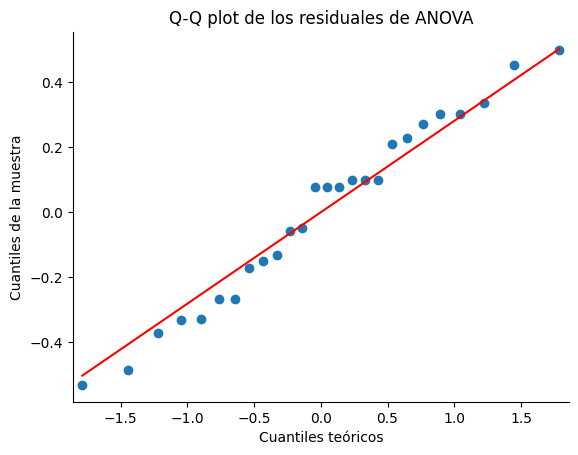

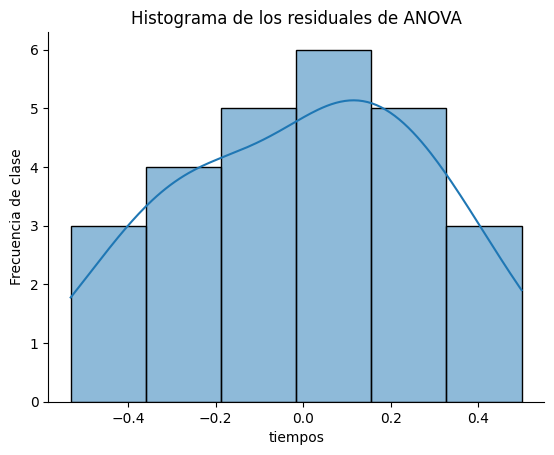

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

Se volvio a utilizar para revisar nuevamente la normalidad. Se obtuvo un valor p de 0.5855, por lo que se considera que se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

con_tratam = df[df['tratamiento'] == "con_tratam"]["porcentaje_de_producto_defectuoso_boxcox"]
sin_tratam= df[df['tratamiento'] == "sin_tratam"]["porcentaje_de_producto_defectuoso_boxcox"]


estadistico, valor_p_levene = levene(
    con_tratam,
    sin_tratam,

    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")



Test de Levene (Brown-Forsythe)
Estadístico = 0.3797
Valor-p = 0.5436


Se realizó para comprobar si la transformación mejoró la igualdad de varianzas por lo que se obtuvo un valor p de 0.5436, por lo que ahora se cumple este supuesto.

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1     group2   meandiff p-adj lower  upper  reject
---------------------------------------------------------
con_tratam sin_tratam   0.8806   0.0 0.6437 1.1175   True
---------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

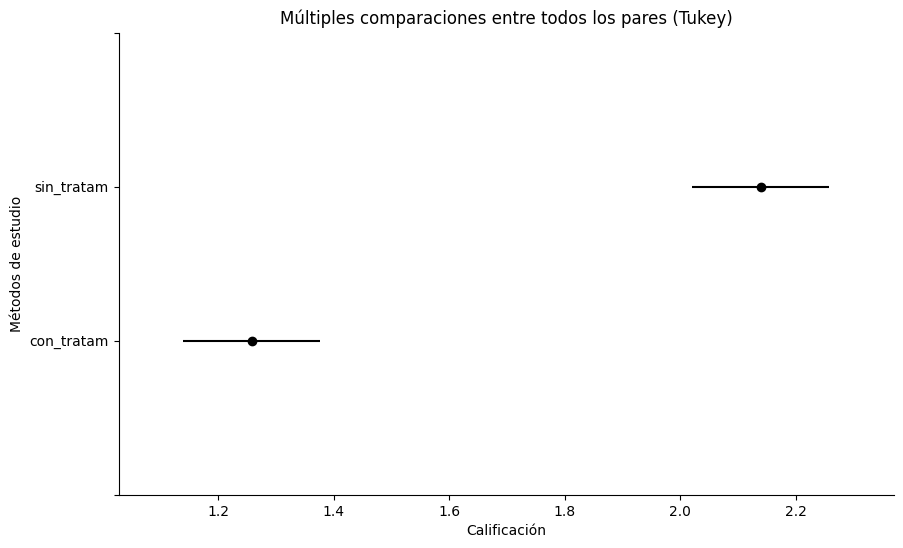

In [ ]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['porcentaje_de_producto_defectuoso_boxcox'], # Variable de respuesta
    groups=df['tratamiento'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Métodos de estudio", xlabel="Calificación")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

ahora comparamos los dos grupos y confirmar dónde se encontraba la diferencia. Se encontró una diferencia significativa entre los productos fabricados con tratamiento y sin tratamiento.

In [ ]:
from scipy.stats import kruskal

# Separar las calificaciones por tratamiento
con_tratam = df[df["tratamiento"] == "con_tratam"]["porcentaje_de_producto_defectuoso"]
sin_tratam = df[df["tratamiento"] == "sin_tratam"]["porcentaje_de_producto_defectuoso"]

# Prueba de Kruskal-Wallis
estadistico, valor_p = kruskal(
   con_tratam ,
   sin_tratam ,
    )

print(f"Estadístico de Kruskal-Wallis: {estadistico:.4f}")
print(f"Valor-p: {valor_p:.4f}")

Estadístico de Kruskal-Wallis: 18.8422
Valor-p: 0.0000


In [ ]:
!pip install scikit-posthocs

In [ ]:
import scikit_posthocs as sp

# Dunn test con corrección de Bonferroni
resultado = sp.posthoc_dunn(
    df,
    val_col="porcentaje_de_producto_defectuoso",
    group_col="tratamiento",
    p_adjust="bonferroni"
)

resultado.round(4)

,con_tratam,sin_tratam
con_tratam,1.0,0.0
sin_tratam,0.0,1.0


In [ ]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(tratamiento)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

η² (tamaño de efecto): 0.710


In [ ]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["tratamiento"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

η² = 0.7103
f de Cohen = 1.5658
Potencia de la prueba = 1.0000


In [ ]:
n_necesario = analisis_potencia.solve_power(
 effect_size=f_cohen,
 alpha=0.05,
 power=0.80, # Potencia de la prueba
 k_groups=k_grupos
)
print(f"Observaciones totales necesarias: {n_necesario:.2f}")
print(f"Observaciones por grupo: {np.ceil(n_necesario / k_grupos):.0f}")

Observaciones totales necesarias: 5.89
Observaciones por grupo: 3


In [ ]:
df.groupby("tratamiento").mean()

,porcentaje_de_producto_defectuoso,porcentaje_de_producto_defectuoso_boxcox
tratamiento,,
con_tratam,3.838462,1.258159
sin_tratam,10.276923,2.138746


El grupo con tratamiento condiguio un promedio aproximado de 3.84% de productos defectuosos, mientras que el otro grupo consiguio un tratamiento del 10.28%. Esto demuestra que la propuesta de mejora ayuda a reducir los defectos de fabricación.

6. Una compañía farmacéutica desea evaluar el efecto que tiene la cantidad de almidón en la dureza de las tabletas. Se decidió producir lotes con una cantidad determinada de almidón, y que las cantidades de almidón a aprobar fueran 2%, 5% y 10%. La variable de respuesta sería el promedio de la dureza de 20 tabletas de cada lote. Se hicieron 4 réplicas por tratamiento y se obtuvieron los siguientes resultados:

| % de almidón | Dureza               |
|--------------|----------------------|
| 2            | 4.3, 5.2, 4.8, 4.5  |
| 5            | 6.5, 7.3, 6.9, 6.1  |
| 10           | 9.0, 7.8, 8.5, 8.1  |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
porcentaje_de_almidon,dureza
grupo_2, 4.3
grupo_2, 5.2
grupo_2, 4.8
grupo_2, 4.5
grupo_5, 6.5
grupo_5, 7.3
grupo_5, 6.9
grupo_5, 6.1
grupo_10, 9.0
grupo_10, 7.8
grupo_10, 8.5
grupo_10, 8.1
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df


,porcentaje_de_almidon,dureza
0,grupo_2,4.3
1,grupo_2,5.2
2,grupo_2,4.8
3,grupo_2,4.5
4,grupo_5,6.5
5,grupo_5,7.3
6,grupo_5,6.9
7,grupo_5,6.1
8,grupo_10,9.0
9,grupo_10,7.8


In [ ]:

import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente

modelo = ols('dureza ~ C(porcentaje_de_almidon)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.

,sum_sq,df,F,PR(>F)
C(porcentaje_de_almidon),26.7267,2.0,58.1014,0.0
Residual,2.0700,9.0,NaN,NaN


Se realizó para comprobar si los diferentes porcentajes de almidón producían cambios en la dureza de las tabletas. Se obtuvo un valor p de 0.0, por lo que existen diferencias significativas entre los porcentajes.

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1   group2 meandiff p-adj   lower   upper  reject
-------------------------------------------------------
grupo_10 grupo_2    -3.65    0.0 -4.5968 -2.7032   True
grupo_10 grupo_5    -1.65 0.0023 -2.5968 -0.7032   True
 grupo_2 grupo_5      2.0 0.0006  1.0532  2.9468   True
-------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

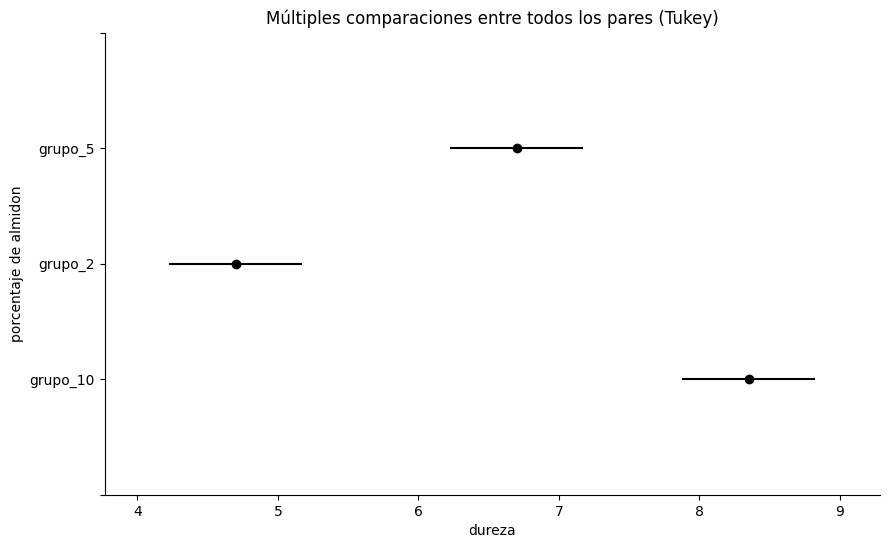

In [ ]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['dureza'], # Variable de respuesta
    groups=df['porcentaje_de_almidon'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="porcentaje de almidon", xlabel="dureza")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

Se implemento el test de tukey para identificar qué porcentajes de almidón presentaban diferencias en la dureza.

In [ ]:
residuales = modelo.resid

valor-p (Shapiro) = 0.4295206808037123


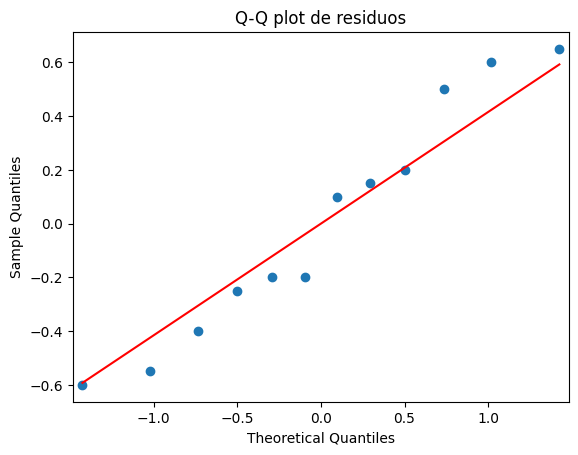

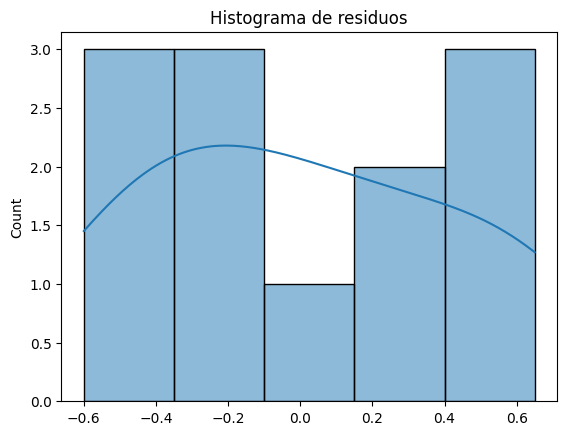

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se aplicó para comprobar si los residuales seguían una distribución normal. Se obtuvo un valor p de 0.4295, por lo que se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
grupo_2 = df[df['porcentaje_de_almidon'] == 'grupo_2']['dureza']
grupo_5 = df[df['porcentaje_de_almidon'] == 'grupo_5']['dureza']
grupo_10 = df[df['porcentaje_de_almidon'] == 'grupo_10']['dureza']

stat, p = levene(grupo_2, grupo_5, grupo_10)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")


Estadístico de Levene: 0.2667
p-valor: 0.7718


Se utilizó para verificar si las varianzas eran similares entre los tres porcentajes de almidón. Se obtuvo un valor p de 0.7718, por lo que se cumple el supuesto.

Se pudo observa que la dureza aumenta conforme se incrementa el porcentaje de almidón, en el nivel de 10%  se obtuvo la mayor dureza promedio, con 8.35 unidades, por lo que es el que genera mayor dureza entre los niveles evaluados.

7. Los datos que se presentan enseguida son rendimientos en toneladas por hectárea de un pasto con tres niveles de fertilización nitrogenada. El diseño fue completamente aleatorizado, con cinco repeticiones por tratamiento.

| Niveles de nitrógeno | Rendimientos (ton/ha)       |
|-----------------------|----------------------------|
| 1                     | 14.823, 14.676, 14.720, 14.5141, 15.065 |
| 2                     | 25.151, 25.401, 25.131, 25.031, 25.267 |
| 3                     | 32.605, 32.460, 32.256, 32.669, 32.111 |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
nivel_de_nitrogeno,rendimiento
grupo_1, 14.823
grupo_1, 14.676
grupo_1, 14.720
grupo_1, 14.5141
grupo_1, 15.065
grupo_2, 25.151
grupo_2, 25.401
grupo_2, 25.131
grupo_2, 25.031
grupo_2, 25.267
grupo_3, 32.605
grupo_3, 32.460
grupo_3, 32.256
grupo_3, 32.669
grupo_3, 32.111
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,nivel_de_nitrogeno,rendimiento
0,grupo_1,14.8230
1,grupo_1,14.6760
2,grupo_1,14.7200
3,grupo_1,14.5141
4,grupo_1,15.0650
5,grupo_2,25.1510
6,grupo_2,25.4010
7,grupo_2,25.1310
8,grupo_2,25.0310
9,grupo_2,25.2670


In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente

modelo = ols('rendimiento ~ C(nivel_de_nitrogeno)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.

,sum_sq,df,F,PR(>F)
C(nivel_de_nitrogeno),788.3408,2.0,10131.6193,0.0
Residual,0.4669,12.0,NaN,NaN


Se realizó para comprobar si los tres niveles de fertilización nitrogenada producían diferencias en el rendimiento del pasto, ya que se obtuvo un valor p es demaciado pequeño no sindica que existen diferencias significativas.

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj  lower   upper  reject
-----------------------------------------------------
grupo_1 grupo_2  10.4366   0.0 10.1038 10.7694   True
grupo_1 grupo_3  17.6606   0.0 17.3278 17.9934   True
grupo_2 grupo_3    7.224   0.0  6.8912  7.5568   True
-----------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

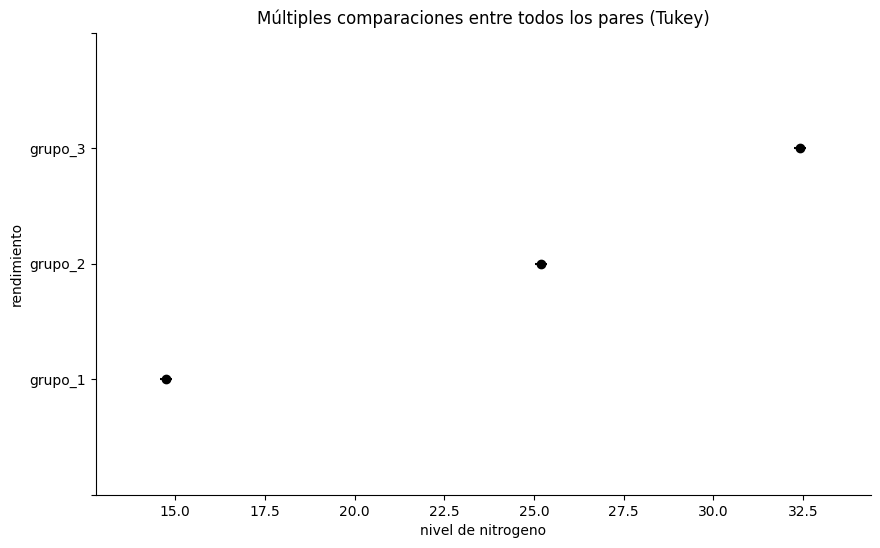

In [ ]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['rendimiento'], # Variable de respuesta
    groups=df['nivel_de_nitrogeno'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="rendimiento", xlabel="nivel de nitrogeno")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

Se realizó para identificar cuáles niveles de nitrógeno producían diferencias significativas. Los resultados mostraron que los tres niveles son diferentes entre sí.

In [ ]:

residuales = modelo.resid

valor-p (Shapiro) = 0.8890610190283172


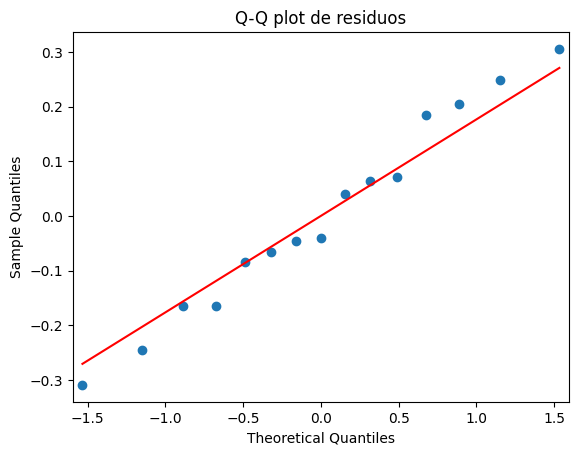

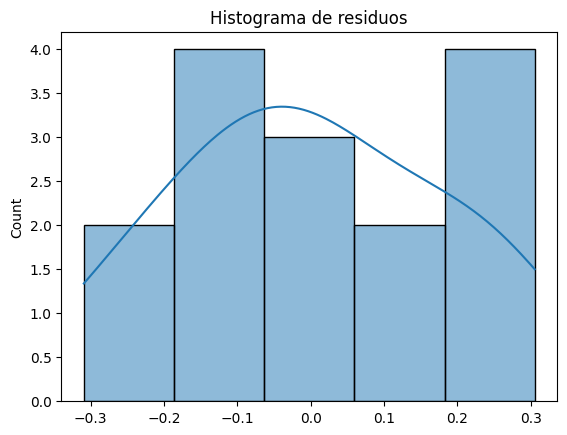

In [ ]:

from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se utilizó para comprobar si los residuales presentaban una distribución normal. Se obtuvo un valor p de 0.8890, por lo que se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
grupo_1 = df[df['nivel_de_nitrogeno'] == 'grupo_1']['rendimiento']
grupo_2 = df[df['nivel_de_nitrogeno'] == 'grupo_2']['rendimiento']
grupo_3 = df[df['nivel_de_nitrogeno'] == 'grupo_3']['rendimiento']

stat, p = levene(grupo_1, grupo_2, grupo_3)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

Estadístico de Levene: 0.5372
p-valor: 0.5978


Se aplicó para comprobar si la variabilidad de los rendimientos era similar entre los tres niveles. Se obtuvo un valor p de 0.5978, por lo que se cumple el supuesto.

El nivel 3 de nitrógeno se recomienda ya que presentó el mayor rendimiento promedio, con aproximadamente 32.42 toneladas por hectárea.

8. Un químico del departamento de desarrollo de un laboratorio farmacéutico desea conocer cómo influye el tipo de aglutinante utilizado en tabletas de ampicilina de 500 mg en el porcentaje de friabilidad; para ello, se eligen los siguientes aglutinantes: polivinilpirrolidona (PVP), carboximetilcelulosa sódica (CMC) y grenetina (Gre). Los resultados del diseño experimental son los siguientes:

| Aglutinante | % de friabilidad          |
|-------------|---------------------------|
| PVP         | 0.485, 0.250, 0.073, 0.205, 0.161 |
| CMC         | 9.64, 9.37, 9.53, 9.86, 9.79       |
| Gre         | 0.289, 0.275, 0.612, 0.152, 0.137  |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
aglutinante,porcentaje_de_friabilidad
PVP, 0.485
PVP, 0.250
PVP, 0.073
PVP, 0.205
PVP, 0.161
CMC, 9.64
CMC, 9.37
CMC, 9.53
CMC, 9.86
CMC, 9.79
Gre, 0.289
Gre, 0.275
Gre, 0.612
Gre, 0.152
Gre, 0.137
'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df



,aglutinante,porcentaje_de_friabilidad
0,PVP,0.485
1,PVP,0.250
2,PVP,0.073
3,PVP,0.205
4,PVP,0.161
5,CMC,9.640
6,CMC,9.370
7,CMC,9.530
8,CMC,9.860
9,CMC,9.790


In [ ]:

import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente

modelo = ols('porcentaje_de_friabilidad ~ C(aglutinante)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.

,sum_sq,df,F,PR(>F)
C(aglutinante),292.9210,2.0,4420.9726,0.0
Residual,0.3975,12.0,NaN,NaN


Se realizó para comprobar si el tipo de aglutinante influía en el porcentaje de friabilidad de las tabletas. Se obtuvo un valor p menor a 0.05, por lo que existen diferencias significativas entre los aglutinantes.

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
   CMC    Gre   -9.345   0.0 -9.6521 -9.0379   True
   CMC    PVP  -9.4032   0.0 -9.7103 -9.0961   True
   Gre    PVP  -0.0582  0.87 -0.3653  0.2489  False
---------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

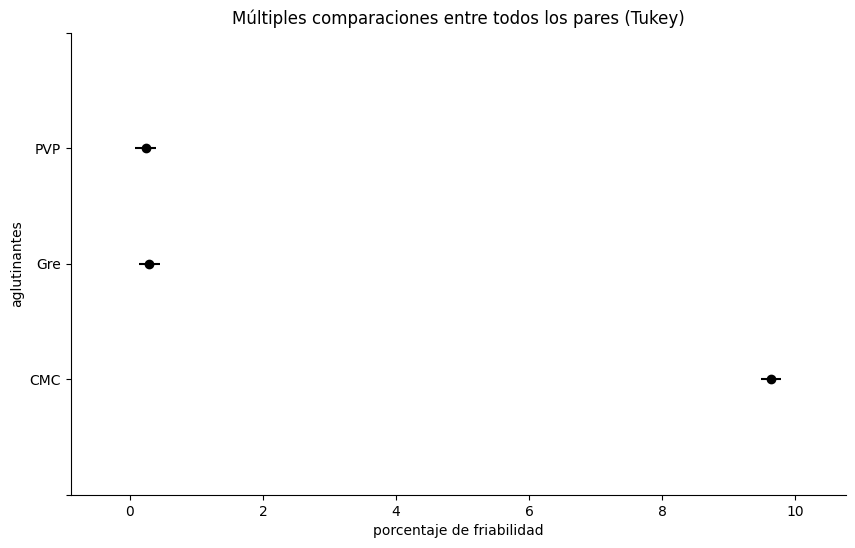

In [ ]:

# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['porcentaje_de_friabilidad'], # Variable de respuesta
    groups=df['aglutinante'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="aglutinantes", xlabel="porcentaje de friabilidad")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")


Se realizó para identificar cuáles aglutinantes presentaban diferencias significativas. Los resultados mostraron que CMC presenta diferencias con PVP y grenetina, mientras que PVP y grenetina no presentan diferencias significativas entre sí.

In [ ]:

residuales = modelo.resid

valor-p (Shapiro) = 0.42143454193876007


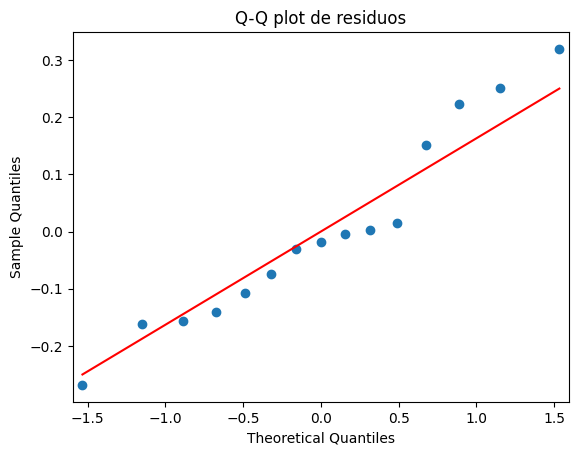

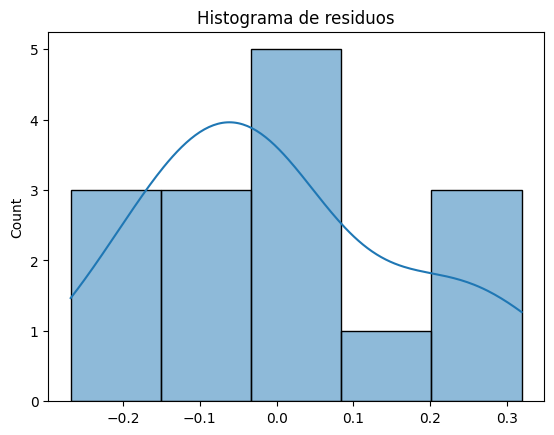

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se aplicó para comprobar si los residuales seguían una distribución normal y Se obtuvo un valor p de 0.4214, por lo que si se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
PVP = df[df['aglutinante'] == 'PVP']['porcentaje_de_friabilidad']
CMC = df[df['aglutinante'] == 'CMC']['porcentaje_de_friabilidad']
Gre = df[df['aglutinante'] == 'Gre']['porcentaje_de_friabilidad']

stat, p = levene(PVP, CMC, Gre)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

Estadístico de Levene: 0.2250
p-valor: 0.8018


Se utilizó para comprobar si las varianzas eran similares entre los tres aglutinantes. Se obtuvo un valor p de 0.8018, por lo que se cumple este supuesto.

El aglutinante PVP obtuvo un promedio de friabilidad de 0.235%, mientras que grenetina obtuvo 0.293% y CMC 9.638%. Por lo tanto, PVP presenta el menor porcentaje promedio de friabilidad y es la alternativa más conveniente si se busca minimizar esta característica.

9. Se cultivaron cuatro diferentes clonas de *agave tequilana* bajo un mismo esquema de manejo. Se quiere saber qué clona es la que responde mejor a dicho manejo, evaluando el nivel de respuesta con el porcentaje de azúcares reductores totales en base húmeda. Los datos se muestran a continuación:

| Clona | Porcentaje de azúcares reductores totales |
|-------|------------------------------------------|
| 1     | 8.69, 6.68, 6.83, 6.43, 10.30            |
| 2     | 8.00, 16.41, 12.43, 10.99, 15.53         |
| 3     | 17.39, 13.73, 15.62, 17.05, 15.42        |
| 4     | 10.37, 9.16, 8.83, 4.40, 10.38           |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
clona,porcentaje_de_azucares_reductores_totales
grupo_1, 8.69
grupo_1, 6.68
grupo_1, 6.83
grupo_1, 6.43
grupo_1, 10.30
grupo_2, 8.00
grupo_2, 16.41
grupo_2, 12.43
grupo_2, 10.99
grupo_2, 15.53
grupo_3, 17.39
grupo_3, 13.73
grupo_3, 15.62
grupo_3, 17.05
grupo_3, 15.42
grupo_4, 10.37
grupo_4, 9.16
grupo_4, 8.83
grupo_4, 4.40
grupo_4, 10.38

'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,clona,porcentaje_de_azucares_reductores_totales
0,grupo_1,8.69
1,grupo_1,6.68
2,grupo_1,6.83
3,grupo_1,6.43
4,grupo_1,10.30
5,grupo_2,8.00
6,grupo_2,16.41
7,grupo_2,12.43
8,grupo_2,10.99
9,grupo_2,15.53


In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente

modelo = ols('porcentaje_de_azucares_reductores_totales ~ C(clona)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.

,sum_sq,df,F,PR(>F)
C(clona),209.9072,3.0,12.3271,0.0002
Residual,90.8168,16.0,NaN,NaN


Se realizó para comprobar si existían diferencias en el porcentaje de azúcares reductores entre las cuatro clonas. Se obtuvo un valor p de 0.0002, por lo que existen diferencias significativas.

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
grupo_1 grupo_2    4.886 0.0237   0.575  9.197   True
grupo_1 grupo_3    8.056 0.0003   3.745 12.367   True
grupo_1 grupo_4    0.842 0.9428  -3.469  5.153  False
grupo_2 grupo_3     3.17 0.1939  -1.141  7.481  False
grupo_2 grupo_4   -4.044 0.0699  -8.355  0.267  False
grupo_3 grupo_4   -7.214  0.001 -11.525 -2.903   True
-----------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

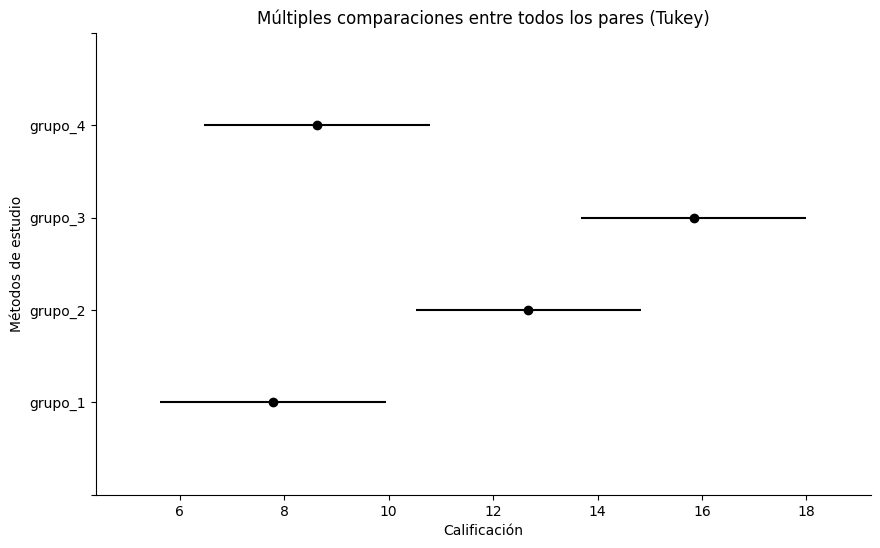

In [ ]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['porcentaje_de_azucares_reductores_totales'], # Variable de respuesta
    groups=df['clona'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="Métodos de estudio", xlabel="Calificación")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

Se realizó para identificar entre cuáles clonas existían diferencias significativas, Se encontraron diferencias entre las clonas 1 y 2, 1 y 3, así como entre 3 y 4. En las demás comparaciones no se encontraron diferencias relevantes.

In [ ]:

residuales = modelo.resid

valor-p (Shapiro) = 0.7677173153296


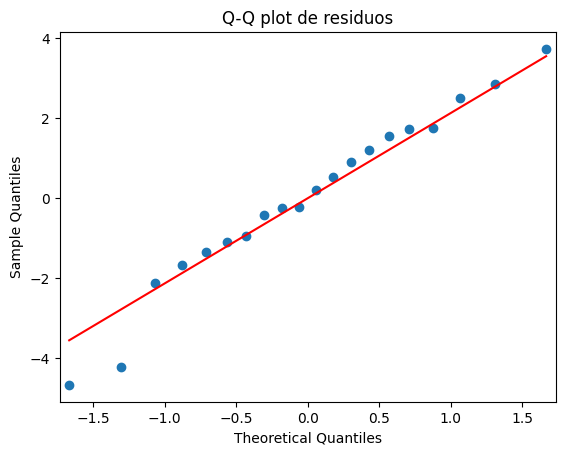

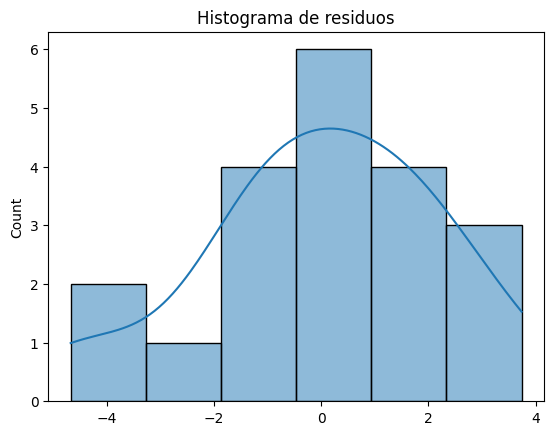

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se aplicó para comprobar si los residuales presentaban una distribución normal. Se obtuvo un valor p de 0.7677, por lo que se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
grupo_1 = df[df['clona'] == 'grupo_1']['porcentaje_de_azucares_reductores_totales']
grupo_2 = df[df['clona'] == 'grupo_2']['porcentaje_de_azucares_reductores_totales']
grupo_3 = df[df['clona'] == 'grupo_3']['porcentaje_de_azucares_reductores_totales']
grupo_4 = df[df['clona'] == 'grupo_4']['porcentaje_de_azucares_reductores_totales']
stat, p = levene(grupo_1, grupo_2, grupo_3, grupo_4)

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

Estadístico de Levene: 0.9749
p-valor: 0.4290


Se utilizó para verificar si las varianzas de las cuatro clonas eran similares. Se obtuvo un valor p de 0.4290, por lo que se cumple el supuesto.

la mejor altenativa seria el clona 3 ya que presentó el mayor porcentaje promedio de azúcares reductores, con aproximadamente 15.84%. Por lo tanto, representa la mejor alternativa si se busca obtener una mayor cantidad de azúcares.

10. Uno de los defectos que causan mayor desperdicio en la manufactura de discos ópticos compactos son los llamados “cometas”. Típicamente, se trata de una partícula que opone resistencia al fluido en la etapa de entintado. Se quiere comprobar de manera experimental la efectividad de un tratamiento de limpieza de partículas que está basado en fuerza centrípeta y aire ionizado. A 12 lotes de 50 CD se les aplica el tratamiento y a otros 12 lotes no se les aplica; en cada caso se mide el porcentaje de discos que presentan cometas, los resultados son los siguientes:

| Con tratamiento      | Sin tratamiento      |
|----------------------|----------------------|
| 5.30   | 8.02  |
| 4.03   | 13.18 |
| 4.00   | 7.15  |
| 2.56   | 9.11  |
| 5.06   | 8.23  |
| 4.06   | 16.3  |
| 2.08   | 9.20  |
| 4.03   | 6.35  |
| 2.04   | 7.15  |
| 1.18   | 8.66  |


In [ ]:
import pandas as pd
from io import StringIO

datos = '''
tratamientos,porcentaje_de_cometas
con_tratamiento, 5.30
con_tratamiento, 4.03
con_tratamiento, 4.00
con_tratamiento, 2.56
con_tratamiento, 5.06
con_tratamiento, 4.06
con_tratamiento, 2.08
con_tratamiento, 4.03
con_tratamiento, 2.04
con_tratamiento, 1.18
sin_tratamiento, 8.02
sin_tratamiento, 13.18
sin_tratamiento, 7.15
sin_tratamiento, 9.11
sin_tratamiento, 8.23
sin_tratamiento, 16.3
sin_tratamiento, 9.20
sin_tratamiento, 6.35
sin_tratamiento, 7.15
sin_tratamiento, 8.66

'''

df = pd.read_csv(StringIO(datos))
df.reset_index(drop=True, inplace=True)

df

,tratamientos,porcentaje_de_cometas
0,con_tratamiento,5.30
1,con_tratamiento,4.03
2,con_tratamiento,4.00
3,con_tratamiento,2.56
4,con_tratamiento,5.06
5,con_tratamiento,4.06
6,con_tratamiento,2.08
7,con_tratamiento,4.03
8,con_tratamiento,2.04
9,con_tratamiento,1.18


In [ ]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Hipótesis:
# H0: mu_1 = mu_2 = mu_3
# H1: al menos una media es diferente

modelo = ols('porcentaje_de_cometas ~ C(tratamientos)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4) # round(4) es para redondear a 4 decimales.

,sum_sq,df,F,PR(>F)
C(tratamientos),174.1090,1.0,30.6057,0.0
Residual,102.3981,18.0,NaN,NaN


Se realizó para comprobar si el tratamiento de limpieza reducía significativamente el porcentaje de discos que presentaban cometas. Se obtuvo un valor p de 0.0, por lo que existe una diferencia significativa entre los grupos.

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
     group1          group2     meandiff p-adj lower upper reject
-----------------------------------------------------------------
con_tratamiento sin_tratamiento    5.901   0.0  3.66 8.142   True
-----------------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

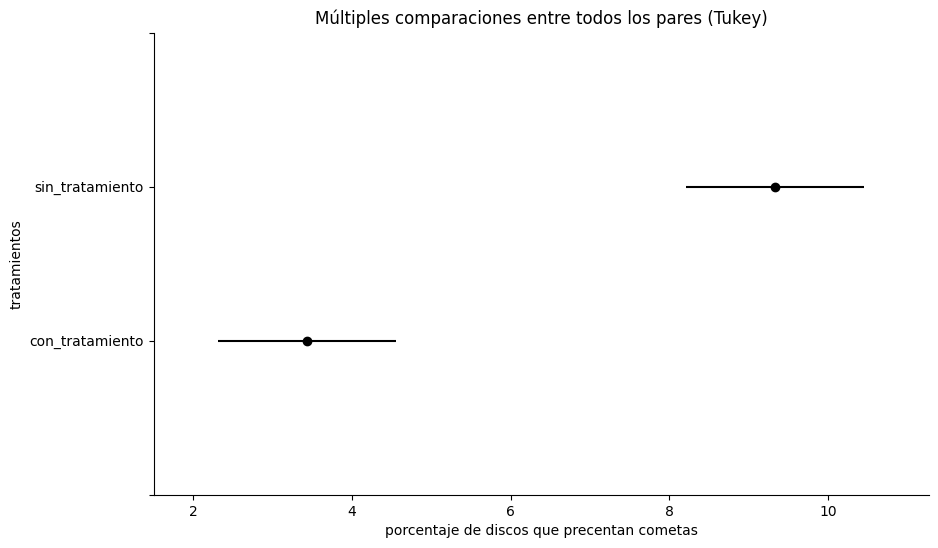

In [ ]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['porcentaje_de_cometas'], # Variable de respuesta
    groups=df['tratamientos'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="tratamientos", xlabel="porcentaje de discos que precentan cometas")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")


Se aplicó para identificar si existían diferencias entre los discos con tratamiento y sin tratamiento. Se encontró una diferencia significativa entre ambos grupos.

In [ ]:

residuales = modelo.resid

valor-p (Shapiro) = 0.013152795271816857


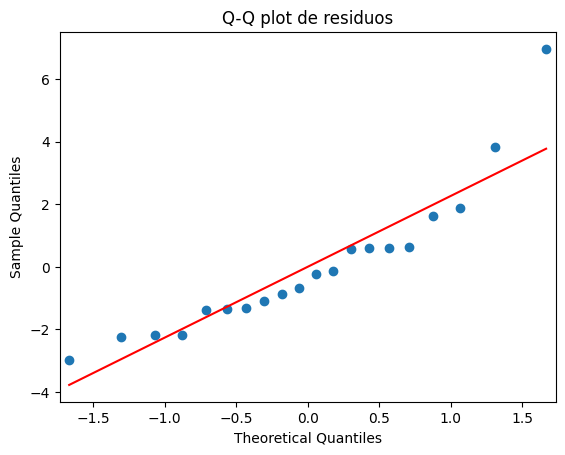

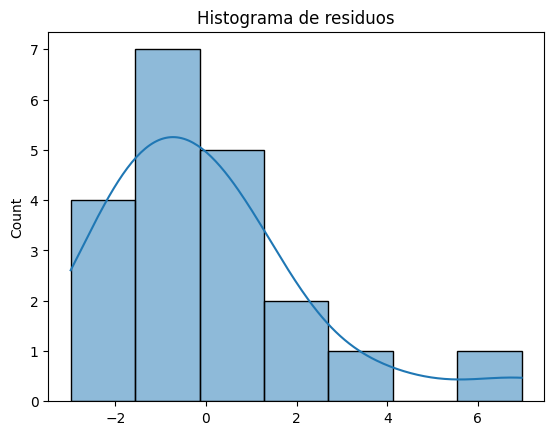

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns

# Prueba de Shapiro-Wilk
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de residuos")
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de residuos")
plt.show()

Se utilizó para comprobar si los residuales presentaban una distribución normal. Se obtuvo un valor p de 0.01315, menor a 0.05, por lo que no se cumplía adecuadamente este supuesto.

In [ ]:
from scipy.stats import levene

# Separar por grupos

# grupo_tal = df[df["categórica de interés"] == "cada uno de los valores categóricos"]["variable de respuesta"]
con_tratamiento = df[df['tratamientos'] == 'con_tratamiento']['porcentaje_de_cometas']
sin_tratamiento = df[df['tratamientos'] == 'sin_tratamiento']['porcentaje_de_cometas']


stat, p = levene(con_tratamiento, sin_tratamiento, )

print(f"Estadístico de Levene: {stat:.4f}")
print(f"p-valor: {p:.4f}")

Estadístico de Levene: 1.1180
p-valor: 0.3043


Se aplicó para comprobar si las varianzas de los grupos eran similares. Se obtuvo un valor p de 0.3043, por lo que se cumple el supuesto de igualdad de varianzas.

Lambda óptimo: 0.32061169162391906


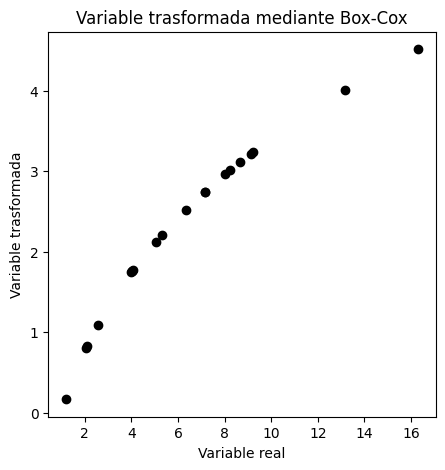

In [ ]:
# Si no se cumple el supuesto de normalidad o el de homoscedasticidad
from scipy.stats import boxcox
import matplotlib.pyplot as plt

# Transformación mediante el método box-cox
# Solo funciona si Y > 0

df["porcentaje_de_cometas_boxcox"], lambda_opt = boxcox(df["porcentaje_de_cometas"])
print(f"Lambda óptimo: {lambda_opt}")

plt.figure(figsize = (5, 5), dpi = 100)
plt.scatter(df["porcentaje_de_cometas"], df["porcentaje_de_cometas_boxcox"], color = "black")
plt.title("Variable trasformada mediante Box-Cox")
plt.xlabel("Variable real")
plt.ylabel("Variable trasformada")
plt.show()

Se aplicó debido a que los residuales no cumplían con el supuesto de normalidad. Su finalidad fue mejorar la distribución de los datos para realizar nuevamente el análisis.

In [ ]:
df

,tratamientos,porcentaje_de_cometas,porcentaje_de_cometas_boxcox
0,con_tratamiento,5.30,2.204887
1,con_tratamiento,4.03,1.757241
2,con_tratamiento,4.00,1.745573
3,con_tratamiento,2.56,1.097026
4,con_tratamiento,5.06,2.126373
5,con_tratamiento,4.06,1.768850
6,con_tratamiento,2.08,0.825494
7,con_tratamiento,4.03,1.757241
8,con_tratamiento,2.04,0.801013
9,con_tratamiento,1.18,0.169985


In [ ]:
# ANOVA de un factor (DCA)
# H0: mu_1 = mu_2 = mu_3
# H1: Al menos una media es diferente
# alpha = 0.05

import statsmodels.api as sm
from statsmodels.formula.api import ols

# respuesta ~ C(factor)
modelo = ols('porcentaje_de_cometas_boxcox ~ C(tratamientos)', data=df).fit()

tabla_anova = sm.stats.anova_lm(modelo, typ=2)

tabla_anova.round(4)


,sum_sq,df,F,PR(>F)
C(tratamientos),15.8598,1.0,38.9108,0.0
Residual,7.3367,18.0,NaN,NaN


Se volvió a realizar para comprobar si se mantenían las diferencias entre los grupos después de la transformación. Los resultados conservaron la diferencia significativa.

valor-p (Shapiro) = 0.9455348310737177


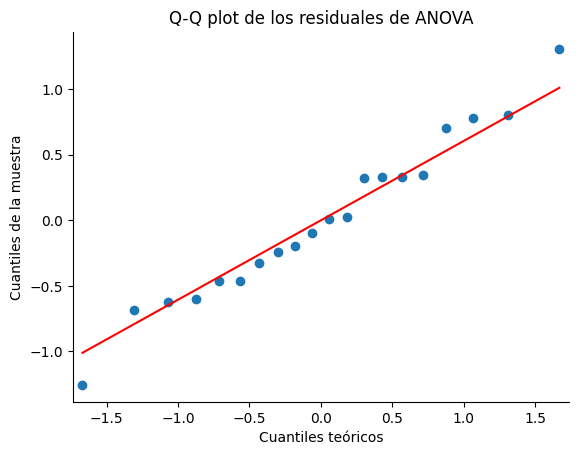

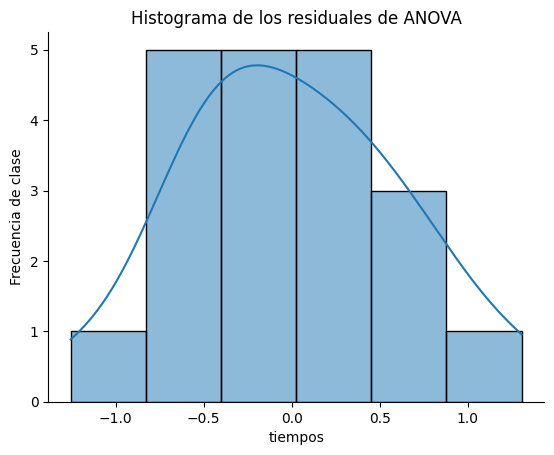

In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

residuales = modelo.resid

# Prueba de Shapiro-Wilk
# H0: Los datos proceden de una distribución normal
# H1: Los datos no proceden de una distribución normal
stat, valor_p_sh = shapiro(residuales)
print(f"valor-p (Shapiro) = {valor_p_sh}")

# Visualización: Q-Q plot
sm.qqplot(residuales, line='s')
plt.title("Q-Q plot de los residuales de ANOVA")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles de la muestra")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

# Histograma
sns.histplot(residuales, kde=True)
plt.title("Histograma de los residuales de ANOVA")
plt.xlabel("tiempos")
plt.ylabel("Frecuencia de clase")
plt.gca().spines[['right', 'top']].set_visible(False)
plt.show()

Se utilizó para comprobar si la transformación mejoró la normalidad. Se obtuvo un valor p de 0.9455, por lo que se cumple este supuesto.

In [ ]:
from scipy.stats import levene

# Test de Levene, centrado en la mediana (Brown-Forsythe)
# H0: todas las varianzas son iguales
# H1: al menos una varianza es distinta al resto

con_tratamiento = df[df['tratamientos'] == "con_tratamiento"]["porcentaje_de_cometas_boxcox"]
sin_tratamiento = df[df['tratamientos'] == "sin_tratamiento"]["porcentaje_de_cometas_boxcox"]


estadistico, valor_p_levene = levene(
   con_tratamiento ,
   sin_tratamiento ,

    center="median"
)

print("\nTest de Levene (Brown-Forsythe)")
print(f"Estadístico = {estadistico:.4f}")
print(f"Valor-p = {valor_p_levene:.4f}")



Test de Levene (Brown-Forsythe)
Estadístico = 0.1523
Valor-p = 0.7009


Se realizó para comprobar nuevamente la igualdad de varianzas. Se obtuvo un valor p de 0.7009, por lo que también se cumple este supuesto.

        Multiple Comparison of Means - Tukey HSD, FWER=0.05        
     group1          group2     meandiff p-adj lower  upper  reject
-------------------------------------------------------------------
con_tratamiento sin_tratamiento    1.781   0.0 1.1812 2.3808   True
-------------------------------------------------------------------


Text(0.5, 1.0, 'Múltiples comparaciones entre todos los pares (Tukey)')

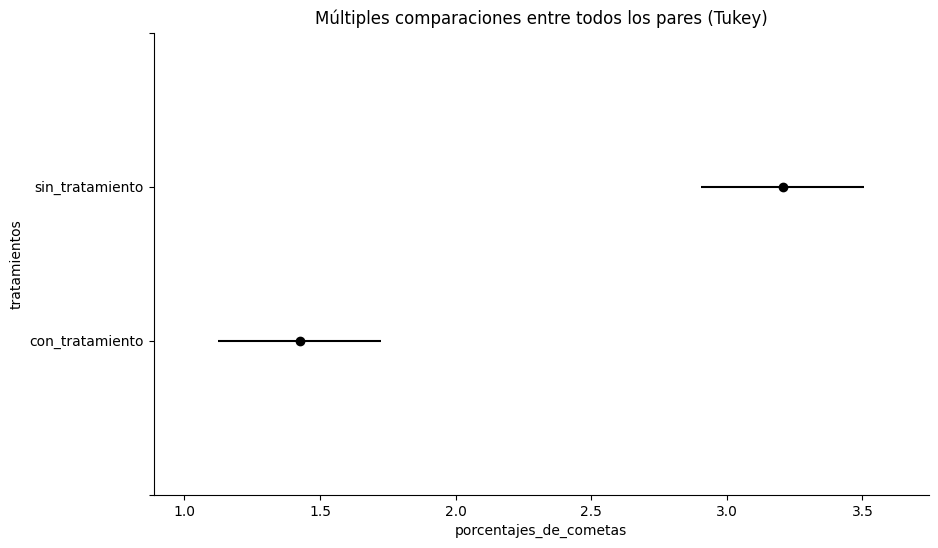

In [ ]:
# Prueba pos-hoc, porque se debe hacer después de ANOVA
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt

nivel_de_significancia = 0.05

# Prueba de Tukey
tukey = pairwise_tukeyhsd(
    endog=df['porcentaje_de_cometas_boxcox'], # Variable de respuesta
    groups=df['tratamientos'],  # Variable categorica nominal
    alpha=nivel_de_significancia) # nivel de significancia

# Mostrar los resultados
print(tukey)

# Gráfico de las diferencias entre grupos
tukey.plot_simultaneous(ylabel="tratamientos", xlabel="porcentajes_de_cometas")

plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior
plt.title("Múltiples comparaciones entre todos los pares (Tukey)")

In [ ]:
from scipy.stats import kruskal

# Separar las calificaciones por tratamiento
con_tratamiento = df[df["tratamientos"] == "con_tratamiento"]["porcentaje_de_cometas"]
sin_tratamiento = df[df["tratamientos"] == "sin_tratamiento"]["porcentaje_de_cometas"]


# Prueba de Kruskal-Wallis
estadistico, valor_p = kruskal(con_tratamiento, sin_tratamiento, )

print(f"Estadístico de Kruskal-Wallis: {estadistico:.4f}")
print(f"Valor-p: {valor_p:.4f}")


Estadístico de Kruskal-Wallis: 14.3072
Valor-p: 0.0002


In [ ]:
import scikit_posthocs as sp

# Dunn test con corrección de Bonferroni
resultado = sp.posthoc_dunn(
    df,
    val_col="porcentaje_de_cometas",
    group_col="tratamientos",
    p_adjust="bonferroni"
)

resultado.round(4)


,con_tratamiento,sin_tratamiento
con_tratamiento,1.0000,0.0002
sin_tratamiento,0.0002,1.0000


In [ ]:
df.groupby("tratamientos").mean()

,porcentaje_de_cometas,porcentaje_de_cometas_boxcox
tratamientos,,
con_tratamiento,3.434,1.425368
sin_tratamiento,9.335,3.206370


In [ ]:
# η² (eta cuadrado)	Tamaño del efecto
# ~0.01	              Pequeño
# ~0.06	              Mediano
# ~0.14 o más	        Grande

# Se interpreta como el coeficiente de determinación

# Estos valores pueden variar según la disciplina. En estudios de ciencias
# sociales, un η² de 0.06 puede ser muy significativo;
# en física o ingeniería, quizá se espera más.

eta_squared = tabla_anova['sum_sq']['C(tratamientos)'] / tabla_anova['sum_sq'].sum()
print(f"η² (tamaño de efecto): {eta_squared:.3f}")

η² (tamaño de efecto): 0.684


In [ ]:
from statsmodels.stats.power import FTestAnovaPower
import numpy as np
alpha = 0.05
k_grupos = df["tratamientos"].nunique()
n_total = len(df)
# Tamaño de efecto para ANOVA
f_cohen = np.sqrt(eta_squared / (1 - eta_squared))
# Potencia de la prueba ANOVA
analisis_potencia = FTestAnovaPower()
potencia = analisis_potencia.power(
 effect_size=f_cohen,
 nobs=n_total,
 alpha=alpha,
 k_groups=k_grupos
)
print(f"η² = {eta_squared:.4f}")
print(f"f de Cohen = {f_cohen:.4f}")
print(f"Potencia de la prueba = {potencia:.4f}")

η² = 0.6837
f de Cohen = 1.4703
Potencia de la prueba = 1.0000


In [ ]:
n_necesario = analisis_potencia.solve_power(
 effect_size=f_cohen,
 alpha=0.05,
 power=0.80, # Potencia de la prueba
 k_groups=k_grupos
)
print(f"Observaciones totales necesarias: {n_necesario:.2f}")
print(f"Observaciones por grupo: {np.ceil(n_necesario / k_grupos):.0f}")

Observaciones totales necesarias: 6.27
Observaciones por grupo: 4
